# 04 Elo Rating
Elo gives every team one strength number. Before each game we turn the rating gap into a home-win probability, and after the game we update both ratings with the result. It needs no feature table: only the order of games and who won.

### Step 1: imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, log_loss, confusion_matrix)

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8a85"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left", "legend.frameon": False})

### Step 2: load and clean `games.csv`
Same cleaning as notebook 02: drop the duplicate games, the games with no stats, and all preseason games.

In [2]:
games = pd.read_csv("../src/dataset/games.csv")

pct = [c for c in games.columns if "PCT" in c]
games[pct] = games[pct].round(3)                       # remove float noise (0.34299999 -> 0.343)
games = games.drop_duplicates("GAME_ID")               # 29 games written twice
games = games[games["PTS_home"].notna()]               # 99 games with no stats and a placeholder label
games = games[games["GAME_ID"] // 10_000_000 != 1]     # preseason games (game id starts with 1)

games["GAME_DATE"] = pd.to_datetime(games["GAME_DATE_EST"])
# 2020 bubble restart: every game at a neutral site, so "home" is only a label
games["NEUTRAL_SITE"] = (games["SEASON"] == 2019) & (games["GAME_DATE"] >= "2020-07-30")
games = games.sort_values(["GAME_DATE", "GAME_ID"]).reset_index(drop=True)

print(len(games), "games")   # should be 24848

24848 games


### Step 3: split by season (never shuffled)
Train on 2003-2016, validate on 2017-2018, test on 2019-2022. The model always learns from the past and is scored on later games.

In [3]:
def season_split(season):
    if season <= 2016:
        return "train"
    if season <= 2018:
        return "validation"
    return "test"

games["SPLIT"] = games["SEASON"].map(season_split)
y = games["HOME_TEAM_WINS"]
is_train, is_val, is_test = (games["SPLIT"] == s for s in ("train", "validation", "test"))

games.groupby("SPLIT", sort=False).agg(games=("HOME_TEAM_WINS", "size"),
                                       home_win_rate=("HOME_TEAM_WINS", "mean")).round(3)

,games,home_win_rate
SPLIT,,
train,18110,0.600
validation,2624,0.589
test,4114,0.554


### Step 4: evaluation (same cell in every model notebook)
Every model gives a probability that the home team wins. We predict "home win" when it is at least 0.5, then report accuracy, precision, recall, F1, ROC-AUC and log loss.

In [4]:
def evaluate(name, y_true, y_prob, threshold=0.5):
    y_prob = np.clip(np.asarray(y_prob, dtype=float), 1e-6, 1 - 1e-6)
    y_pred = (y_prob >= threshold).astype(int)
    return {"model": name,
            "accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1": f1_score(y_true, y_pred, zero_division=0),
            "roc_auc": roc_auc_score(y_true, y_prob),
            "log_loss": log_loss(y_true, y_prob, labels=[0, 1])}

def plot_cm(ax, y_true, y_prob, title):
    cm = confusion_matrix(y_true, (np.asarray(y_prob) >= 0.5).astype(int), labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["away win", "home win"], yticklabels=["away win", "home win"])
    ax.set_xlabel("predicted"); ax.set_ylabel("actual"); ax.set_title(title)

### Step 5: the Elo function
- Every team starts at 1500.
- **Before** a game, the home team's win probability is `1 / (1 + 10^(-(home_rating + home_adv - away_rating) / 400))`. The 2020 bubble games get no home advantage.
- **After** the game, the winner gains `K * (result - probability)` points and the loser loses the same amount. An upset moves the ratings more.
- At the start of a new season each rating is pulled back toward 1500 (`carryover` = share of the gap that is kept).

The probability is recorded before the update, so a game's Elo only uses earlier games. No leakage.

In [5]:
def run_elo(games, k=20, home_adv=100, carryover=0.75, base=1500):
    rating, last_season = {}, {}
    elo_home, elo_away, prob = [], [], []
    for h, a, season, win, neutral in zip(games["HOME_TEAM_ID"], games["VISITOR_TEAM_ID"], games["SEASON"],
                                          games["HOME_TEAM_WINS"], games["NEUTRAL_SITE"]):
        for team in (h, a):
            if team not in rating:
                rating[team] = base
            elif last_season[team] != season:              # new season: pull back toward 1500
                rating[team] = base + carryover * (rating[team] - base)
            last_season[team] = season
        rh, ra = rating[h], rating[a]
        p = 1 / (1 + 10 ** (-(rh + (0 if neutral else home_adv) - ra) / 400))
        elo_home.append(rh); elo_away.append(ra); prob.append(p)   # record BEFORE the update
        rating[h] = rh + k * (win - p)
        rating[a] = ra - k * (win - p)
    return pd.DataFrame({"ELO_HOME": elo_home, "ELO_AWAY": elo_away, "ELO_PROB_HOME": prob}, index=games.index)

elo_default = run_elo(games)
elo_default.head()

,ELO_HOME,ELO_AWAY,ELO_PROB_HOME
0,1500.0,1500.0000,0.640065
1,1500.0,1500.0000,0.640065
2,1500.0,1500.0000,0.640065
3,1500.0,1492.8013,0.649555
4,1500.0,1500.0000,0.640065


### Step 6: tune K, home advantage and carry-over
Elo has three settings. We try a small grid and pick the one with the lowest **validation** log loss. The test seasons are not used here.

In [6]:
import itertools, time

grid = {"k": [10, 15, 20, 25, 30], "home_adv": [50, 75, 100, 125], "carryover": [0.5, 0.75, 1.0]}

t0 = time.time()
rows = []
for k, ha, co in itertools.product(grid["k"], grid["home_adv"], grid["carryover"]):
    p = run_elo(games, k=k, home_adv=ha, carryover=co)["ELO_PROB_HOME"]
    rows.append({"k": k, "home_adv": ha, "carryover": co,
                 "train_log_loss": log_loss(y[is_train], p[is_train]),
                 "val_log_loss": log_loss(y[is_val], p[is_val]),
                 "val_accuracy": accuracy_score(y[is_val], (p[is_val] >= 0.5).astype(int))})
tuning = pd.DataFrame(rows).sort_values("val_log_loss").reset_index(drop=True)
print(len(tuning), "settings tried in %.1fs" % (time.time() - t0))

best = tuning.iloc[0]
print("best: K =", best["k"], "| home_adv =", best["home_adv"], "| carryover =", best["carryover"])
tuning.head(8).round(4)

60 settings tried in 1.6s
best: K = 20.0 | home_adv = 75.0 | carryover = 0.5


,k,home_adv,carryover,train_log_loss,val_log_loss,val_accuracy
0,20,75,0.50,0.6056,0.6181,0.6608
1,20,75,0.75,0.6052,0.6182,0.6585
2,15,75,0.75,0.6064,0.6186,0.6536
3,25,75,0.50,0.6054,0.6188,0.6562
4,15,75,0.50,0.6075,0.6190,0.6570
5,25,75,0.75,0.6054,0.6193,0.6585
6,20,50,0.50,0.6087,0.6196,0.6582
7,20,50,0.75,0.6083,0.6197,0.6601


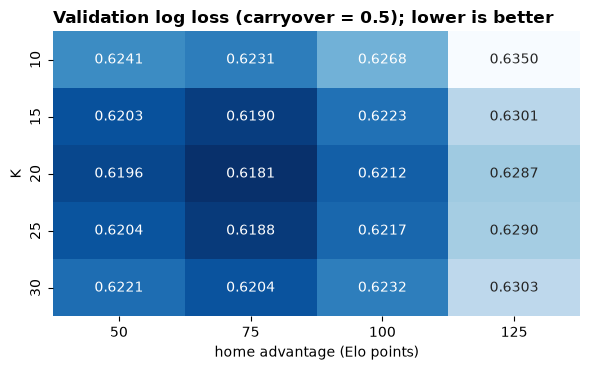

In [7]:
co_best = best["carryover"]
heat = tuning[tuning["carryover"] == co_best].pivot(index="k", columns="home_adv", values="val_log_loss")

fig, ax = plt.subplots(figsize=(6, 3.8))
sns.heatmap(heat, annot=True, fmt=".4f", cmap="Blues_r", cbar=False, ax=ax)
ax.set_xlabel("home advantage (Elo points)"); ax.set_ylabel("K")
ax.set_title(f"Validation log loss (carryover = {co_best}); lower is better")
plt.tight_layout(); plt.show()

### Step 7: evaluate the best Elo on train, validation and test

In [8]:
elo = run_elo(games, k=int(best["k"]), home_adv=best["home_adv"], carryover=best["carryover"])
p_elo = elo["ELO_PROB_HOME"]
p_majority = np.full(len(games), y[is_train].mean())   # majority baseline for comparison

rows = []
for part, mask in (("train", is_train), ("validation", is_val), ("test", is_test)):
    rows.append(evaluate(f"majority ({part})", y[mask], p_majority[mask]))
    rows.append(evaluate(f"Elo ({part})", y[mask], p_elo[mask]))
results = pd.DataFrame(rows).set_index("model")
results.round(4)

,accuracy,precision,recall,f1,roc_auc,log_loss
model,,,,,,
majority (train),0.5996,0.5996,1.0000,0.7497,0.5000,0.6732
Elo (train),0.6684,0.6848,0.8283,0.7497,0.7107,0.6056
majority (validation),0.5888,0.5888,1.0000,0.7412,0.5000,0.6775
Elo (validation),0.6608,0.6712,0.8311,0.7426,0.6964,0.6181
majority (test),0.5544,0.5544,1.0000,0.7134,0.5000,0.6914
Elo (test),0.6276,0.6225,0.8343,0.7130,0.6733,0.6446


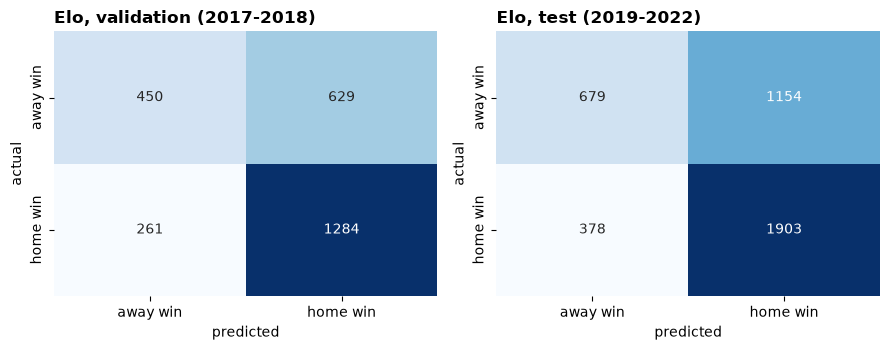

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
plot_cm(axes[0], y[is_val], p_elo[is_val], "Elo, validation (2017-2018)")
plot_cm(axes[1], y[is_test], p_elo[is_test], "Elo, test (2019-2022)")
plt.tight_layout(); plt.show()

### Step 8: is the Elo probability trustworthy? (calibration)
If Elo says 70%, the home team should win about 70% of those games. Points on the diagonal mean the probabilities are honest.

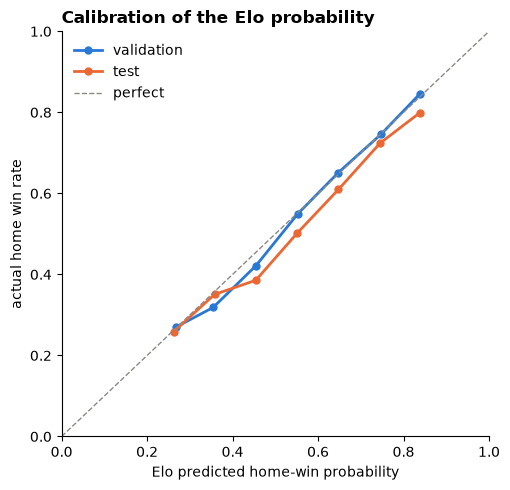

In [10]:
fig, ax = plt.subplots(figsize=(5.2, 5))
for part, mask, color in (("validation", is_val, BLUE), ("test", is_test, ORANGE)):
    bins = pd.cut(p_elo[mask], np.linspace(0, 1, 11))
    cal = pd.DataFrame({"pred": p_elo[mask], "won": y[mask]}).groupby(bins, observed=True).agg(
        pred=("pred", "mean"), won=("won", "mean"), n=("won", "size"))
    cal = cal[cal["n"] >= 30]                          # skip bins with very few games
    ax.plot(cal["pred"], cal["won"], marker="o", ms=5, lw=2, color=color, label=part)
ax.plot([0, 1], [0, 1], color=GRAY, ls="--", lw=1, label="perfect")
ax.set_xlabel("Elo predicted home-win probability"); ax.set_ylabel("actual home win rate")
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.legend(loc="upper left")
ax.set_title("Calibration of the Elo probability")
plt.tight_layout(); plt.show()

### Step 9: Elo over time for a few teams

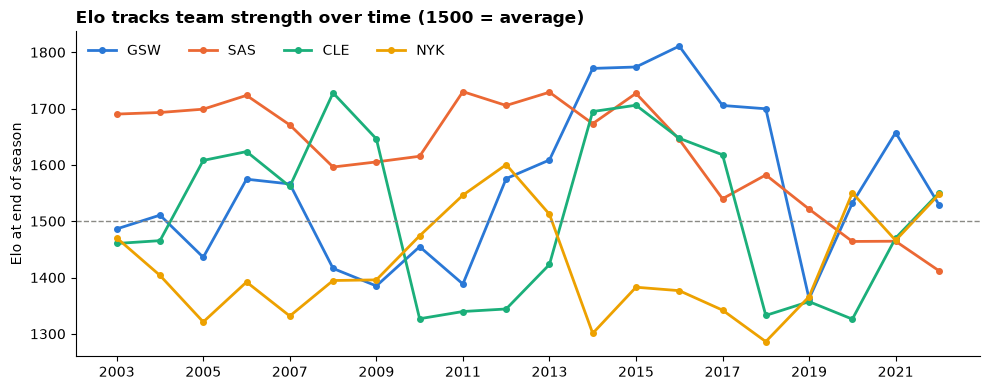

In [11]:
abbr = pd.read_csv("../src/dataset/teams.csv").set_index("TEAM_ID")["ABBREVIATION"]
cols = {"season": games["SEASON"], "date": games["GAME_DATE"]}
long = pd.concat([pd.DataFrame({**cols, "team": games["HOME_TEAM_ID"], "elo": elo["ELO_HOME"]}),
                  pd.DataFrame({**cols, "team": games["VISITOR_TEAM_ID"], "elo": elo["ELO_AWAY"]})])
long["team"] = long["team"].map(abbr)

# rating going into each team's last game of the season
season_end = long.sort_values("date").groupby(["team", "season"])["elo"].last().unstack(0)

fig, ax = plt.subplots(figsize=(10, 4))
for team, color in (("GSW", BLUE), ("SAS", ORANGE), ("CLE", "#1baf7a"), ("NYK", "#eda100")):
    ax.plot(season_end.index, season_end[team], color=color, lw=2, marker="o", ms=4, label=team)
ax.axhline(1500, color=GRAY, ls="--", lw=1)
ax.set_xticks(range(2003, 2023, 2)); ax.set_ylabel("Elo at end of season")
ax.legend(ncol=4, loc="upper left")
ax.set_title("Elo tracks team strength over time (1500 = average)")
plt.tight_layout(); plt.show()

### Step 10: observation
Observation: Tuning on validation picked K = 20, home advantage = 75 and carryover = 0.5 (validation log loss 0.6181). The grid is flat near the top: the best few settings differ by less than 0.001 in log loss, so Elo is not sensitive to its settings, except that a home advantage of 125 is clearly worse. With the best settings Elo reaches 66.84% accuracy on train, 66.08% on validation and 62.76% on test, about 7 points above the majority baseline on every split (ROC-AUC 0.71 / 0.70 / 0.67).

Fit: train and validation are close (66.84% vs 66.08%, log loss 0.6056 vs 0.6181), so Elo is not overfitting. With only 3 settings it cannot memorize the data. If anything it underfits: one number per team cannot use rest days or recent form. The drop on test (62.76%) comes mostly from the COVID seasons. The calibration plot shows the test line below the diagonal, meaning Elo still expects the usual home edge and over-predicts home wins (1,154 test games it called home wins were away wins).

Next steps: use the Elo probability as a feature in logistic regression and the tree models together with the rest and form features, and consider a smaller home advantage for recent seasons.